## Bussiness Problem

* The system predicts whether a patient is likely to have sepsis based on clinical parameters and provides an explanation for the prediction.

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv(r"D:\Explainable AI for Sepsis Risk Prediction\data\sepsis_icu_synthetic.csv")

In [3]:
df

,subject_id,age,gender,weight_kg,height_cm,bmi,ethnicity,insurance,hr_mean,hr_max,...,apache_iv,qsofa,sirs_criteria,gcs_total,icu_los_hours,hospital_admit_source,icu_admit_time_hour,day_of_week,readmission_30day,sepsis_label
0,37464,72,M,99.5,160.6,38.6,Black,Medicare,83.0,98.7,...,47.9,2,1,12,27.0,OR,15,2,1,1
1,34024,62,M,101.2,164.5,37.4,Other,Private,97.5,105.8,...,35.0,1,1,6,21.5,Transfer,21,2,0,0
2,65291,74,M,64.0,167.2,22.9,White,Private,100.6,105.8,...,29.0,1,1,11,46.7,ED,19,6,0,0
3,79118,87,M,75.1,180.5,23.0,White,Medicare,95.5,114.7,...,35.6,1,1,7,1.7,ED,8,2,0,0
4,34897,61,M,52.5,158.4,NaN,Hispanic,Private,86.7,106.7,...,34.6,1,1,8,64.0,Transfer,9,2,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,51856,64,M,73.0,177.0,NaN,Black,Private,75.2,92.9,...,31.0,2,0,12,9.1,ED,19,6,0,0
4996,66102,75,F,62.3,190.0,17.3,Asian,Medicare,98.3,109.8,...,41.6,1,1,9,11.2,ED,22,5,0,0
4997,51381,89,F,74.2,175.7,24.1,White,Medicare,102.7,119.3,...,75.9,2,2,9,55.2,ED,22,3,0,1
4998,59828,77,M,64.1,163.7,23.9,White,Medicare,89.8,108.1,...,29.8,1,0,8,34.4,ED,19,3,0,0


In [4]:
df.shape

(5000, 77)

In [5]:
df.columns.tolist()

['subject_id',
 'age',
 'gender',
 'weight_kg',
 'height_cm',
 'bmi',
 'ethnicity',
 'insurance',
 'hr_mean',
 'hr_max',
 'hr_min',
 'hr_std',
 'sbp_mean',
 'sbp_max',
 'sbp_min',
 'sbp_std',
 'dbp_mean',
 'dbp_max',
 'dbp_min',
 'dbp_std',
 'map_mean',
 'temp_celsius_mean',
 'temp_celsius_max',
 'temp_celsius_min',
 'temp_celsius_std',
 'spo2_mean',
 'spo2_min',
 'spo2_max',
 'spo2_std',
 'respiratory_rate_mean',
 'respiratory_rate_max',
 'respiratory_rate_min',
 'respiratory_rate_std',
 'wbc',
 'lactate_mmol',
 'creatinine',
 'platelet_count',
 'bilirubin_total',
 'glucose',
 'ph_arterial',
 'pao2_fio2_ratio',
 'inr',
 'sodium',
 'potassium',
 'chloride',
 'bicarbonate',
 'hematocrit',
 'hemoglobin',
 'diabetes',
 'hypertension',
 'chf',
 'copd',
 'chronic_kidney_disease',
 'liver_disease',
 'immunosuppression',
 'cad',
 'atrial_fibrillation',
 'cancer_active',
 'vasopressors_flag',
 'mechanical_ventilation',
 'fio2_percent',
 'antibiotics_24h',
 'fluids_ml_24h',
 'sedation_score',
 

In [6]:
df['sepsis_label'].value_counts()

sepsis_label
0    4250
1     750
Name: count, dtype: int64

### The Target column having imbalance.

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 77 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   subject_id                   5000 non-null   int64  
 1   age                          5000 non-null   int64  
 2   gender                       5000 non-null   str    
 3   weight_kg                    5000 non-null   float64
 4   height_cm                    5000 non-null   float64
 5   bmi                          4749 non-null   float64
 6   ethnicity                    5000 non-null   str    
 7   insurance                    5000 non-null   str    
 8   hr_mean                      5000 non-null   float64
 9   hr_max                       5000 non-null   float64
 10  hr_min                       5000 non-null   float64
 11  hr_std                       5000 non-null   float64
 12  sbp_mean                     5000 non-null   float64
 13  sbp_max                      

In [8]:
df.dtypes

subject_id                 int64
age                        int64
gender                       str
weight_kg                float64
height_cm                float64
                          ...   
hospital_admit_source        str
icu_admit_time_hour        int64
day_of_week                int64
readmission_30day          int64
sepsis_label               int64
Length: 77, dtype: object

In [9]:
df.isna().sum()

subject_id               0
age                      0
gender                   0
weight_kg                0
height_cm                0
                        ..
hospital_admit_source    0
icu_admit_time_hour      0
day_of_week              0
readmission_30day        0
sepsis_label             0
Length: 77, dtype: int64

In [10]:
df.isna().sum().sum()

np.int64(7350)

In [11]:
lis = {}
for col in df.columns.tolist():
    if df[col].isnull().sum()>0:
        lis[col] = int(df[col].isnull().sum())

lis

{'bmi': 251,
 'map_mean': 163,
 'wbc': 527,
 'creatinine': 550,
 'platelet_count': 550,
 'bilirubin_total': 557,
 'glucose': 565,
 'ph_arterial': 502,
 'inr': 558,
 'sodium': 531,
 'potassium': 504,
 'chloride': 497,
 'bicarbonate': 511,
 'hematocrit': 554,
 'hemoglobin': 530}

In [12]:
one_category = [col for col in df.columns if df[col].nunique()<=1]

In [13]:
one_category

['mechanical_ventilation']

In [14]:
df.select_dtypes('str')

,gender,ethnicity,insurance,hospital_admit_source
0,M,Black,Medicare,OR
1,M,Other,Private,Transfer
2,M,White,Private,ED
3,M,White,Medicare,ED
4,M,Hispanic,Private,Transfer
...,...,...,...,...
4995,M,Black,Private,ED
4996,F,Asian,Medicare,ED
4997,F,White,Medicare,ED
4998,M,White,Medicare,ED


In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df['subject_id'].duplicated().sum()

np.int64(0)

In [17]:
l = []
for col in df.columns:
    if df[col].nunique() <= 10:
        print(f"\n{col}")
        print(df[col].unique())
        l.append(col)
print(len(l))


gender
<StringArray>
['M', 'F', 'Mael']
Length: 3, dtype: str

ethnicity
<StringArray>
['Black', 'Other', 'White', 'Hispanic', 'Asian']
Length: 5, dtype: str

insurance
<StringArray>
['Medicare', 'Private', 'Medicaid', 'Self-pay']
Length: 4, dtype: str

diabetes
[1 0]

hypertension
[1 0]

chf
[1 0]

copd
[1 0]

chronic_kidney_disease
[1 0]

liver_disease
[0 1]

immunosuppression
[0 1]

cad
[1 0]

atrial_fibrillation
[0 1]

cancer_active
[0 1]

vasopressors_flag
[1 0]

mechanical_ventilation
[1]

antibiotics_24h
[1 0]

sedation_score
[-4.  1. -1. -5. -2.  0. -3.]

insulin_infusion_flag
[0 1]

qsofa
[2 1 0 3]

sirs_criteria
[1 2 0 3 4]

gcs_total
[12  6 11  7  8 10  9 15]

hospital_admit_source
<StringArray>
['OR', 'Transfer', 'ED', 'Direct']
Length: 4, dtype: str

day_of_week
[2 6 1 7 4 3 5]

readmission_30day
[1 0]

sepsis_label
[1 0]
25


In [18]:
df.dtypes.value_counts()

float64    49
int64      24
str         4
Name: count, dtype: int64

In [19]:
df.describe()

,subject_id,age,weight_kg,height_cm,bmi,hr_mean,hr_max,hr_min,hr_std,sbp_mean,...,sofa_score,apache_iv,qsofa,sirs_criteria,gcs_total,icu_los_hours,icu_admit_time_hour,day_of_week,readmission_30day,sepsis_label
count,5000.00000,5000.000000,5000.000000,5000.000000,4749.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,...,5000.0000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000.000000
mean,55017.28520,64.271600,74.882440,170.042780,25.835965,90.632460,102.280580,77.282000,8.009020,126.533460,...,8.3982,36.258860,1.202600,0.952600,9.125000,48.171620,12.8858,3.760800,0.053800,0.150000
std,14621.76943,14.287136,18.609579,9.498858,5.876215,21.764086,20.302219,20.276711,2.923621,21.087581,...,1.9435,14.332177,0.487033,0.969815,2.115814,48.757138,6.4812,1.931613,0.225645,0.357107
min,30009.00000,18.000000,45.000000,150.000000,12.500000,40.000000,47.200000,21.600000,0.000000,49.500000,...,3.0000,1.300000,0.000000,0.000000,6.000000,1.000000,0.0000,1.000000,0.000000,0.000000
25%,42132.50000,55.000000,63.500000,163.400000,21.600000,76.975000,89.300000,63.900000,6.000000,112.500000,...,7.0000,26.700000,1.000000,0.000000,7.000000,13.600000,7.0000,2.000000,0.000000,0.000000
50%,55733.50000,65.000000,73.700000,170.100000,25.600000,88.300000,100.200000,75.400000,8.000000,126.700000,...,8.0000,34.500000,1.000000,1.000000,9.000000,33.500000,14.0000,4.000000,0.000000,0.000000
75%,67780.25000,74.000000,84.400000,176.625000,29.600000,100.500000,113.100000,88.200000,10.000000,141.200000,...,9.0000,43.525000,1.000000,1.000000,11.000000,66.400000,19.0000,5.000000,0.000000,0.000000
max,79966.00000,89.000000,241.900000,190.000000,48.400000,239.500000,215.300000,186.200000,18.800000,208.000000,...,17.0000,101.200000,3.000000,4.000000,15.000000,500.000000,23.0000,7.000000,1.000000,1.000000


## Data Cleaning

In [20]:
cleaned_df = df.copy()

In [21]:
columns_to_remove = [
    "subject_id",
    "mechanical_ventilation",
    "icu_los_hours",
    "sofa_score",
    "apache_iv",
    "qsofa",
    "sirs_criteria",
    "vasopressors_flag",
    "vasopressor_dose_mcg_kg_min",
    "antibiotics_24h",
    "fluids_ml_24h",
    "sedation_score",
    "insulin_infusion_flag"
]

cleaned_df.drop(
    columns=columns_to_remove,
    inplace=True,
    errors="ignore"
)

print("Shape after removing unwanted columns:", cleaned_df.shape)

Shape after removing unwanted columns: (5000, 64)


In [22]:
print(cleaned_df["gender"].value_counts())

gender
M       2821
F       2178
Mael       1
Name: count, dtype: int64


In [23]:
cleaned_df["gender"] = cleaned_df["gender"].replace({
    "Mael": "M"
})

print(cleaned_df["gender"].value_counts())

gender
M    2822
F    2178
Name: count, dtype: int64


In [24]:
invalid_spo2 = cleaned_df["spo2_max"] > 100

print("Invalid SpO2 values:", invalid_spo2.sum())

cleaned_df.loc[
    invalid_spo2,
    "spo2_max"
] = np.nan

Invalid SpO2 values: 425


In [25]:
invalid_temp_mean = (
    (cleaned_df["temp_celsius_mean"] < cleaned_df["temp_celsius_min"]) |
    (cleaned_df["temp_celsius_mean"] > cleaned_df["temp_celsius_max"])
)

print("Invalid temperature mean values:", invalid_temp_mean.sum())

cleaned_df.loc[
    invalid_temp_mean,
    "temp_celsius_mean"
] = np.nan

Invalid temperature mean values: 13


In [26]:
invalid_hr_mean = (
    (cleaned_df["hr_mean"] < cleaned_df["hr_min"]) |
    (cleaned_df["hr_mean"] > cleaned_df["hr_max"])
)

print("Invalid HR mean values:", invalid_hr_mean.sum())

cleaned_df.loc[
    invalid_hr_mean,
    "hr_mean"
] = np.nan

Invalid HR mean values: 53


In [27]:
invalid_sbp_mean = (
    (cleaned_df["sbp_mean"] < cleaned_df["sbp_min"]) |
    (cleaned_df["sbp_mean"] > cleaned_df["sbp_max"])
)

print("Invalid SBP mean values:", invalid_sbp_mean.sum())

cleaned_df.loc[
    invalid_sbp_mean,
    "sbp_mean"
] = np.nan

Invalid SBP mean values: 31


In [28]:
invalid_dbp_mean = (
    (cleaned_df["dbp_mean"] < cleaned_df["dbp_min"]) |
    (cleaned_df["dbp_mean"] > cleaned_df["dbp_max"])
)

print("Invalid DBP mean values:", invalid_dbp_mean.sum())

cleaned_df.loc[
    invalid_dbp_mean,
    "dbp_mean"
] = np.nan

Invalid DBP mean values: 31


In [29]:
duplicate_count = cleaned_df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


In [30]:
if duplicate_count > 0:
    cleaned_df = cleaned_df.drop_duplicates().reset_index(drop=True)

print("Shape:", cleaned_df.shape)

Shape: (5000, 64)


In [31]:
cleaned_df["shock_index"] = (
    cleaned_df["hr_mean"] /
    cleaned_df["sbp_mean"]
)

In [32]:
cleaned_df["pulse_pressure"] = (
    cleaned_df["sbp_mean"] -
    cleaned_df["dbp_mean"]
)

In [33]:
cleaned_df["oxygen_respiratory_risk"] = (
    cleaned_df["respiratory_rate_mean"] /
    cleaned_df["spo2_mean"]
)

In [34]:
cleaned_df["temperature_range"] = (
    cleaned_df["temp_celsius_max"] -
    cleaned_df["temp_celsius_min"]
)

In [35]:
cleaned_df["kidney_risk"] = (
    (cleaned_df["creatinine"] > 1.3).astype(int) |
    (cleaned_df["chronic_kidney_disease"] == 1).astype(int)
).astype(int)

In [36]:
cleaned_df["blood_abnormality_score"] = (
    (cleaned_df["wbc"] > 12000).astype(int) +
    (cleaned_df["wbc"] < 4000).astype(int) +
    (cleaned_df["platelet_count"] < 150000).astype(int) +
    (cleaned_df["hemoglobin"] < 12).astype(int)
)

In [37]:
cleaned_df["lactate_risk"] = (
    cleaned_df["lactate_mmol"] >= 2.0
).astype(int)

In [38]:
cleaned_df["glucose_diabetes_risk"] = (
    (cleaned_df["glucose"] >= 126).astype(int) |
    (cleaned_df["diabetes"] == 1).astype(int)
).astype(int)

In [39]:
selected_features = [
    "age",
    "gender",
    "bmi",
    "shock_index",
    "pulse_pressure",
    "temp_celsius_mean",
    "oxygen_respiratory_risk",
    "map_mean",
    "pao2_fio2_ratio",
    "bilirubin_total",
    "ph_arterial",
    "sodium",
    "gcs_total",
    "kidney_risk",
    "blood_abnormality_score",
    "sepsis_label"
]

cleaned_df = cleaned_df[selected_features]

print("Final dataset shape:", cleaned_df.shape)
print(cleaned_df.columns.tolist())

Final dataset shape: (5000, 16)
['age', 'gender', 'bmi', 'shock_index', 'pulse_pressure', 'temp_celsius_mean', 'oxygen_respiratory_risk', 'map_mean', 'pao2_fio2_ratio', 'bilirubin_total', 'ph_arterial', 'sodium', 'gcs_total', 'kidney_risk', 'blood_abnormality_score', 'sepsis_label']


In [40]:
print(cleaned_df.isnull().sum())

age                          0
gender                       0
bmi                        251
shock_index                 83
pulse_pressure              31
temp_celsius_mean           13
oxygen_respiratory_risk      0
map_mean                   163
pao2_fio2_ratio              0
bilirubin_total            557
ph_arterial                502
sodium                     531
gcs_total                    0
kidney_risk                  0
blood_abnormality_score      0
sepsis_label                 0
dtype: int64


In [41]:
X = cleaned_df.drop(
    columns=["sepsis_label"]
)

y = cleaned_df["sepsis_label"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (5000, 15)
y shape: (5000,)


In [42]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (4000, 15)
X_test: (1000, 15)
y_train: (4000,)
y_test: (1000,)


In [43]:
print("Training target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training target distribution:
sepsis_label
0    3395
1     605
Name: count, dtype: int64

Testing target distribution:
sepsis_label
0    855
1    145
Name: count, dtype: int64


In [44]:
categorical_columns = [
    "gender"
]

numerical_columns = [
    column
    for column in X_train.columns
    if column not in categorical_columns
]

print("Categorical columns:")
print(categorical_columns)

print("\nNumerical columns:")
print(numerical_columns)

Categorical columns:
['gender']

Numerical columns:
['age', 'bmi', 'shock_index', 'pulse_pressure', 'temp_celsius_mean', 'oxygen_respiratory_risk', 'map_mean', 'pao2_fio2_ratio', 'bilirubin_total', 'ph_arterial', 'sodium', 'gcs_total', 'kidney_risk', 'blood_abnormality_score']


In [45]:
for column in numerical_columns:

    median_value = X_train[column].median()

    X_train[column] = X_train[column].fillna(
        median_value
    )

    X_test[column] = X_test[column].fillna(
        median_value
    )

In [46]:
print("Missing values in X_train:")
print(X_train.isnull().sum().sum())

print("\nMissing values in X_test:")
print(X_test.isnull().sum().sum())

Missing values in X_train:
0

Missing values in X_test:
0


In [47]:
for column in categorical_columns:

    mode_value = X_train[column].mode()[0]

    X_train[column] = X_train[column].fillna(
        mode_value
    )

    X_test[column] = X_test[column].fillna(
        mode_value
    )

In [48]:
print("Missing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())

Missing values in X_train: 0
Missing values in X_test: 0


In [49]:
continuous_columns = [
    "age",
    "bmi",
    "shock_index",
    "pulse_pressure",
    "temp_celsius_mean",
    "oxygen_respiratory_risk",
    "map_mean",
    "pao2_fio2_ratio",
    "bilirubin_total",
    "ph_arterial",
    "sodium"
]

In [50]:
for column in continuous_columns:

    Q1 = X_train[column].quantile(0.25)
    Q3 = X_train[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    X_train[column] = X_train[column].clip(
        lower=lower_bound,
        upper=upper_bound
    )

    X_test[column] = X_test[column].clip(
        lower=lower_bound,
        upper=upper_bound
    )

In [51]:
from sklearn.preprocessing import LabelEncoder

gender_encoder = LabelEncoder()

X_train["gender"] = gender_encoder.fit_transform(
    X_train["gender"]
)

X_test["gender"] = gender_encoder.transform(
    X_test["gender"]
)

In [52]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train[numerical_columns] = scaler.fit_transform(
    X_train[numerical_columns]
)

X_test[numerical_columns] = scaler.transform(
    X_test[numerical_columns]
)

In [53]:
X_train.dtypes

age                        float64
gender                       int64
bmi                        float64
shock_index                float64
pulse_pressure             float64
temp_celsius_mean          float64
oxygen_respiratory_risk    float64
map_mean                   float64
pao2_fio2_ratio            float64
bilirubin_total            float64
ph_arterial                float64
sodium                     float64
gcs_total                  float64
kidney_risk                float64
blood_abnormality_score    float64
dtype: object

In [54]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

In [55]:
from sklearn.linear_model import LogisticRegression

In [56]:
lg = LogisticRegression(max_iter=100, random_state=42)

In [57]:
lg.fit(X_train_smote, y_train_smote)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

In [58]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix, classification_report

In [59]:
y_pred_train = lg.predict(X_train_smote)
y_pred_test = lg.predict(X_test)

print("Training Accuracy:", accuracy_score(y_train_smote, y_pred_train))
print("Test Accuracy:", accuracy_score(y_test, y_pred_test))

print("Training F1 Score:", f1_score(y_train_smote, y_pred_train))
print("Test F1 Score:", f1_score(y_test, y_pred_test))

print("Training Precision:", precision_score(y_train_smote, y_pred_train))
print("Test Precision:", precision_score(y_test, y_pred_test))

print("Training Recall:", recall_score(y_train_smote, y_pred_train))
print("Test Recall:", recall_score(y_test, y_pred_test))

print("Confusion Matrix (Test):")
print(confusion_matrix(y_test, y_pred_test))

print("Classification Report (Test):")
print(classification_report(y_test, y_pred_test))

Training Accuracy: 0.9997054491899853
Test Accuracy: 0.999
Training F1 Score: 0.9997055359246172
Test F1 Score: 0.9965635738831615
Training Precision: 0.9994112452163674
Test Precision: 0.9931506849315068
Training Recall: 1.0
Test Recall: 1.0
Confusion Matrix (Test):
[[854   1]
 [  0 145]]
Classification Report (Test):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       855
           1       0.99      1.00      1.00       145

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



In [60]:
from sklearn.tree import DecisionTreeClassifier

In [61]:
dt = DecisionTreeClassifier(random_state=42)

In [62]:
dt.fit(X_train_smote, y_train_smote)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [63]:
y_pred_train = dt.predict(X_train_smote)
y_pred_test = dt.predict(X_test)
print("Training Accuracy:", accuracy_score(y_train_smote, y_pred_train))
print("Test Accuracy:", accuracy_score(y_test, y_pred_test))

print("Training F1 Score:", f1_score(y_train_smote, y_pred_train))
print("Test F1 Score:", f1_score(y_test, y_pred_test))

print("Training Precision:", precision_score(y_train_smote, y_pred_train))
print("Test Precision:", precision_score(y_test, y_pred_test))

print("Training Recall:", recall_score(y_train_smote, y_pred_train))
print("Test Recall:", recall_score(y_test, y_pred_test))

print("Confusion Matrix (Test):")
print(confusion_matrix(y_test, y_pred_test))

print("Classification Report (Test):")
print(classification_report(y_test, y_pred_test))

Training Accuracy: 1.0
Test Accuracy: 1.0
Training F1 Score: 1.0
Test F1 Score: 1.0
Training Precision: 1.0
Test Precision: 1.0
Training Recall: 1.0
Test Recall: 1.0
Confusion Matrix (Test):
[[855   0]
 [  0 145]]
Classification Report (Test):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       855
           1       1.00      1.00      1.00       145

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



In [64]:
from sklearn.model_selection import GridSearchCV

In [65]:
gr = GridSearchCV(
    estimator=dt,
    param_grid={
        "criterion": ["gini", "entropy"],
        "max_depth": [3, 5, 7, 10, None],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4]
    },
    scoring="f1",
    cv=5,
    n_jobs=-1
)

In [66]:
gr.fit(X_train_smote, y_train_smote)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [3, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"ve

In [67]:
gr.best_params_

{'criterion': 'gini',
 'max_depth': 3,
 'min_samples_leaf': 1,
 'min_samples_split': 2}

In [68]:
dt = DecisionTreeClassifier(random_state=42,criterion='gini', max_depth=3, min_samples_leaf=1, min_samples_split=3)

In [69]:
dt.fit(X_train_smote, y_train_smote)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [70]:
y_pred_train = dt.predict(X_train_smote)
y_pred_test = dt.predict(X_test)


print("Training Accuracy:", accuracy_score(y_train_smote, y_pred_train))
print("Test Accuracy:", accuracy_score(y_test, y_pred_test))

print("Training F1 Score:", f1_score(y_train_smote, y_pred_train))
print("Test F1 Score:", f1_score(y_test, y_pred_test))

print("Training Precision:", precision_score(y_train_smote, y_pred_train))
print("Test Precision:", precision_score(y_test, y_pred_test))

print("Training Recall:", recall_score(y_train_smote, y_pred_train))
print("Test Recall:", recall_score(y_test, y_pred_test))

print("Confusion Matrix (Test):")
print(confusion_matrix(y_test, y_pred_test))

print("Classification Report (Test):")
print(classification_report(y_test, y_pred_test))

Training Accuracy: 1.0
Test Accuracy: 1.0
Training F1 Score: 1.0
Test F1 Score: 1.0
Training Precision: 1.0
Test Precision: 1.0
Training Recall: 1.0
Test Recall: 1.0
Confusion Matrix (Test):
[[855   0]
 [  0 145]]
Classification Report (Test):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       855
           1       1.00      1.00      1.00       145

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



In [71]:
from sklearn.ensemble import RandomForestClassifier

In [72]:
rf = RandomForestClassifier(random_state=42)

In [73]:
rf.fit(X_train_smote, y_train_smote)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [74]:
y_pred_train = rf.predict(X_train_smote)
y_pred_test = rf.predict(X_test)
print("Training Accuracy:", accuracy_score(y_train_smote, y_pred_train))
print("Test Accuracy:", accuracy_score(y_test, y_pred_test))

print("Training F1 Score:", f1_score(y_train_smote, y_pred_train))
print("Test F1 Score:", f1_score(y_test, y_pred_test))

print("Training Precision:", precision_score(y_train_smote, y_pred_train))
print("Test Precision:", precision_score(y_test, y_pred_test))

print("Training Recall:", recall_score(y_train_smote, y_pred_train))
print("Test Recall:", recall_score(y_test, y_pred_test))

print("Confusion Matrix (Test):")
print(confusion_matrix(y_test, y_pred_test))

print("Classification Report (Test):")
print(classification_report(y_test, y_pred_test))

Training Accuracy: 1.0
Test Accuracy: 1.0
Training F1 Score: 1.0
Test F1 Score: 1.0
Training Precision: 1.0
Test Precision: 1.0
Training Recall: 1.0
Test Recall: 1.0
Confusion Matrix (Test):
[[855   0]
 [  0 145]]
Classification Report (Test):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       855
           1       1.00      1.00      1.00       145

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



In [75]:
gr = GridSearchCV(
    estimator=rf,
    param_grid={
        "n_estimators": [100, 200],
        "max_depth": [5, 10, 15, None],
        "min_samples_split": [2, 5],
        "min_samples_leaf": [1, 2],
        "max_features": ["sqrt", "log2"]
    },
    scoring="f1",
    cv=5,
    n_jobs=-1
)

In [76]:
gr.fit(X_train_smote, y_train_smote)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [5, 10, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbos

In [77]:
gr.best_params_

{'max_depth': 5,
 'max_features': 'sqrt',
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'n_estimators': 100}

In [78]:
rf = RandomForestClassifier(random_state=42, **gr.best_params_)

In [79]:
rf.fit(X_train_smote, y_train_smote)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

In [80]:
y_pred_train = rf.predict(X_train_smote)
y_pred_test = rf.predict(X_test)
print("Training Accuracy:", accuracy_score(y_train_smote, y_pred_train))
print("Test Accuracy:", accuracy_score(y_test, y_pred_test))

print("Training F1 Score:", f1_score(y_train_smote, y_pred_train))
print("Test F1 Score:", f1_score(y_test, y_pred_test))

print("Training Precision:", precision_score(y_train_smote, y_pred_train))
print("Test Precision:", precision_score(y_test, y_pred_test))

print("Training Recall:", recall_score(y_train_smote, y_pred_train))
print("Test Recall:", recall_score(y_test, y_pred_test))

print("Confusion Matrix (Test):")
print(confusion_matrix(y_test, y_pred_test))

print("Classification Report (Test):")
print(classification_report(y_test, y_pred_test))

Training Accuracy: 1.0
Test Accuracy: 1.0
Training F1 Score: 1.0
Test F1 Score: 1.0
Training Precision: 1.0
Test Precision: 1.0
Training Recall: 1.0
Test Recall: 1.0
Confusion Matrix (Test):
[[855   0]
 [  0 145]]
Classification Report (Test):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       855
           1       1.00      1.00      1.00       145

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



### The final Model is Decision Tree 

In [81]:
dt = DecisionTreeClassifier(random_state=42, criterion='gini', max_depth=3, min_samples_leaf=1, min_samples_split=3)

In [82]:
dt.fit(X_train_smote, y_train_smote)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [83]:
y_pred_train = dt.predict(X_train_smote)
y_pred_test = dt.predict(X_test)

print("Training Accuracy:", accuracy_score(y_train_smote, y_pred_train))
print("Test Accuracy:", accuracy_score(y_test, y_pred_test))

print("Training F1 Score:", f1_score(y_train_smote, y_pred_train))
print("Test F1 Score:", f1_score(y_test, y_pred_test))

print("Training Precision:", precision_score(y_train_smote, y_pred_train))
print("Test Precision:", precision_score(y_test, y_pred_test))

print("Training Recall:", recall_score(y_train_smote, y_pred_train))
print("Test Recall:", recall_score(y_test, y_pred_test))

print("Confusion Matrix (Test):")
print(confusion_matrix(y_test, y_pred_test))

print("Classification Report (Test):")
print(classification_report(y_test, y_pred_test))

Training Accuracy: 1.0
Test Accuracy: 1.0
Training F1 Score: 1.0
Test F1 Score: 1.0
Training Precision: 1.0
Test Precision: 1.0
Training Recall: 1.0
Test Recall: 1.0
Confusion Matrix (Test):
[[855   0]
 [  0 145]]
Classification Report (Test):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       855
           1       1.00      1.00      1.00       145

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



In [84]:
import shap

d:\Explainable AI for Sepsis Risk Prediction\sepsis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [85]:
explainer = shap.TreeExplainer(dt)

In [86]:
shap_values = explainer.shap_values(X_test)

In [91]:
print(np.shape(shap_values))

(1000, 15, 2)


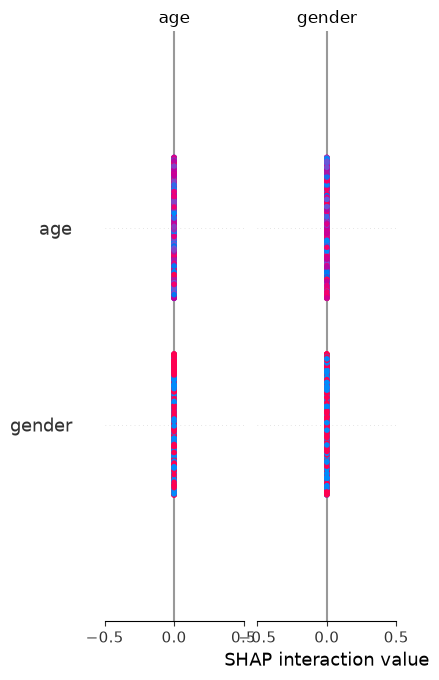

In [95]:
shap.summary_plot(shap_values, X_test, plot_type="bar")

In [98]:
patient_index = 10

patient = X_test.iloc[[patient_index]]

print(patient)

           age  gender      bmi  shock_index  pulse_pressure  \
2464  0.954768       0 -1.83991     2.214324       -0.537887   

      temp_celsius_mean  oxygen_respiratory_risk  map_mean  pao2_fio2_ratio  \
2464           0.124006                 1.036911 -1.161155        -1.982031   

      bilirubin_total  ph_arterial    sodium  gcs_total  kidney_risk  \
2464        -1.024259     0.122699  0.036063  -1.007789     0.300853   

      blood_abnormality_score  
2464                 1.074799  


In [99]:
prediction = dt.predict(patient)

probability = dt.predict_proba(patient)[:, 1]

print("Prediction:", prediction[0])
print("Sepsis probability:", probability[0])

Prediction: 1
Sepsis probability: 1.0
